# Male vs female: comparing two *Drosophila* connectomes

| Dataset in neuPrint | Sex | What it covers |
|---|---|---|
| `hemibrain:v1.2.1` | female | most of the right central brain of one fly |
| `male-cns:v1.0` | male | the complete central nervous system of one fly (brain, optic lobes, ventral nerve cord) |

**Plan**
1. **Orientation** — where is the mushroom body in each brain?
2. **Neuron counts** — how many neurons does each dataset contain?
3. **Neuropils** — size, neurons and synapses of the same brain regions in both sexes.
4. **The α/β lobes** — a detailed male–female comparison: volume, synapses, connections, partners and connection strength.
5. **Neurons that look the same** in both sexes.
6. **Sexually dimorphic and sex-specific neurons** known from the literature.

Every analysis is shown next to a picture of the **neuropil (ROI mesh)** and the **neuron skeletons** it is about. Female plots are pink, male plots are blue.

**Keep in mind:** each dataset is **one animal**, imaged and proofread with different methods, and the hemibrain is cut off at its edges. We therefore compare against neurons that should be the same in both sexes before calling a difference "sexual dimorphism".

## 0. Setup
Run these cells once. The last one defines the plotting helpers — you do not need to read it.

In [ ]:
import importlib.util, subprocess, sys
missing = [p for m, p in {"neuprint": "neuprint-python", "plotly": "plotly"}.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

In [ ]:
import os, re, getpass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
import plotly.graph_objects as go
from neuprint import (Client, NeuronCriteria as NC, fetch_neurons, fetch_adjacencies,
                      merge_neuron_properties, fetch_custom, fetch_skeleton)

pd.set_option("display.max_columns", 30)
VOXEL_UM = 0.008                       # both datasets use 8 nm voxels
VOXEL_UM3 = VOXEL_UM ** 3
SEX_COL = {"female": "#C2185B", "male": "#1565C0"}

In [ ]:
TOKEN = os.environ.get("NEUPRINT_APPLICATION_CREDENTIALS")
if not TOKEN:
    try:
        from google.colab import userdata
        TOKEN = userdata.get("NEUPRINT_TOKEN")
    except Exception:
        pass
if not TOKEN:
    TOKEN = getpass.getpass("Paste your neuPrint token: ")

female = Client("neuprint.janelia.org", "hemibrain:v1.2.1", TOKEN)
male = Client("neuprint.janelia.org", "male-cns:v1.0", TOKEN)
CLIENTS = {"female": female, "male": male}
for sex, c in CLIENTS.items():
    print(f"{sex:6s} -> {c.dataset}")

Paste your neuPrint token: ··········
female -> hemibrain:v1.2.1
male   -> male-cns:v1.0


### Region names
Both datasets name brain regions (ROIs) in a similar way, e.g. `aL(R)` = right α lobe. The cell below looks up each region we need in each dataset and prints what it found. If a name shows `None`, look at the printed list of ROIs and edit `ROI_CANDIDATES`.

In [ ]:
ROI_CANDIDATES = {
    "calyx":       ["CA(R)"],
    "pedunculus":  ["PED(R)"],
    "α lobe":      ["aL(R)"],
    "β lobe":      ["bL(R)"],
    "α′ lobe":     ["a'L(R)"],
    "β′ lobe":     ["b'L(R)"],
    "γ lobe":      ["gL(R)"],
    "antennal lobe": ["AL(R)"],
    "lateral horn":  ["LH(R)"],
    "SMP":  ["SMP(R)"], "SIP": ["SIP(R)"], "SLP": ["SLP(R)"], "CRE": ["CRE(R)"],
    "AOTU": ["AOTU(R)"], "AVLP": ["AVLP(R)"], "LAL": ["LAL(R)"],
    "ellipsoid body": ["EB"], "fan-shaped body": ["FB"], "protocerebral bridge": ["PB"],
}
MB_PARTS = ["calyx", "pedunculus", "α lobe", "β lobe", "α′ lobe", "β′ lobe", "γ lobe"]
MB_COL = {"calyx": "#8D6E63", "pedunculus": "#9E9E9E", "α lobe": "#7B1FA2", "β lobe": "#AB47BC",
          "α′ lobe": "#00897B", "β′ lobe": "#4DB6AC", "γ lobe": "#EF6C00"}

ROI = {}
for sex, c in CLIENTS.items():
    have = set(c.all_rois)
    ROI[sex] = {name: next((r for r in opts if r in have), None) for name, opts in ROI_CANDIDATES.items()}
pd.DataFrame(ROI)

,female,male
calyx,CA(R),CA(R)
pedunculus,PED(R),PED(R)
α lobe,aL(R),aL(R)
β lobe,bL(R),bL(R)
α′ lobe,a'L(R),a'L(R)
β′ lobe,b'L(R),b'L(R)
γ lobe,gL(R),gL(R)
antennal lobe,AL(R),AL(R)
lateral horn,LH(R),LH(R)
SMP,SMP(R),SMP(R)


In [ ]:
# ---------------------------------------------------------------- plotting helpers
_mesh, _skel, MESH_SCALE, ORIENT = {}, {}, {"female": 1.0, "male": 1.0}, {}

# Each view: (horizontal unit vector, vertical unit vector, x label, y label), built from the body axes
# R = towards the fly's right, D = dorsal, A = anterior (worked out per dataset in the calibration cell)
VIEWS = {
    "front": (lambda o: -o["R"], lambda o: o["D"], "fly's left → (µm)", "dorsal ↑ (µm)"),   # looking at the fly's face
    "top":   (lambda o: o["R"], lambda o: o["A"], "fly's right → (µm)", "anterior ↑ (µm)"), # looking down on the head
    "side":  (lambda o: o["A"], lambda o: o["D"], "anterior → (µm)", "dorsal ↑ (µm)"),     # looking from the fly's right
}


def proj(sex, P, view="front"):
    # Project points (N x 3, voxels) onto a 2D anatomical view -> horizontal, vertical (µm)
    h, v, *_ = VIEWS[view]
    P = np.asarray(P, dtype=float) * VOXEL_UM
    return P @ h(ORIENT[sex]), P @ v(ORIENT[sex])


def roi_name(sex, name):
    return ROI[sex].get(name, name) if name in ROI[sex] else name


def roi_mesh(sex, roi):
    # ROI mesh -> (vertices in voxels, faces). Cached.
    key = (sex, roi)
    if key not in _mesh:
        verts, faces = [], []
        for line in CLIENTS[sex].fetch_roi_mesh(roi).decode().splitlines():
            p = line.split()
            if p and p[0] == "v":
                verts.append([float(v) for v in p[1:4]])
            elif p and p[0] == "f":
                faces.append([int(q.split("/")[0]) - 1 for q in p[1:4]])
        _mesh[key] = (np.array(verts), np.array(faces))
    v, f = _mesh[key]
    return v * MESH_SCALE[sex], f


def mesh_volume_um3(sex, roi):
    # Volume enclosed by a closed triangle mesh (divergence theorem), in µm³
    v, f = roi_mesh(sex, roi)
    a, b, c_ = v[f[:, 0]], v[f[:, 1]], v[f[:, 2]]
    return abs(np.einsum("ij,ij->i", a, np.cross(b, c_)).sum()) / 6 * VOXEL_UM3


def skeleton(sex, body):
    if (sex, body) not in _skel:
        _skel[(sex, body)] = fetch_skeleton(int(body), heal=True, client=CLIENTS[sex])
    return _skel[(sex, body)]


def skeleton_lines(sk):
    seg = sk.merge(sk, left_on="link", right_on="rowId", suffixes=("", "_p"))
    return {k: np.c_[seg[k], seg[k + "_p"], np.full(len(seg), np.nan)].ravel() * VOXEL_UM for k in "xyz"}


def draw_rois(ax, sex, names, view="front", colours=None, alpha=0.05, label=True):
    for name in names:
        roi = roi_name(sex, name)
        if roi is None:
            continue
        v, f = roi_mesh(sex, roi)
        h, vv = proj(sex, v, view)
        col = (colours or {}).get(name, "#9E9E9E")
        ax.add_collection(PolyCollection(np.stack([h[f], vv[f]], axis=-1), facecolor=col, edgecolor="none",
                                         alpha=alpha, zorder=0))
        if label:
            ax.plot([], [], c=col, lw=8, alpha=0.6, label=name)
    ax.autoscale_view()


def draw_skeletons(ax, sex, bodies, view="front", colour=None, lw=0.6, max_n=20):
    for body in list(bodies)[:max_n]:
        L = skeleton_lines(skeleton(sex, body))
        h, v = proj(sex, np.c_[L["x"], L["y"], L["z"]] / VOXEL_UM, view)
        ax.plot(h, v, c=colour or SEX_COL[sex], lw=lw, zorder=2)


def finish(ax, view="front", title=""):
    ax.autoscale_view(); ax.set_aspect("equal")
    ax.set_xlabel(VIEWS[view][2]); ax.set_ylabel(VIEWS[view][3]); ax.set_title(title)


def compare_anatomy(rois, neurons=None, view="front", colours=None, title="", alpha=0.06, legend=True):
    # Female and male side by side: ROI meshes + skeletons. neurons = {"female": [ids], "male": [ids]}
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
    for ax, sex in zip(axes, ["female", "male"]):
        draw_rois(ax, sex, rois, view, colours, alpha)
        if neurons and len(neurons.get(sex, [])):
            draw_skeletons(ax, sex, neurons[sex], view)
            ax.plot([], [], c=SEX_COL[sex], lw=2, label=f"{min(len(neurons[sex]), 20)} skeleton(s)")
        elif neurons is not None:
            ax.text(0.5, 0.95, "no neurons of this type", transform=ax.transAxes, ha="center", color="grey")
        finish(ax, view, f"{sex}: {CLIENTS[sex].dataset}")
    if legend:
        axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9, frameon=False)
    fig.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()


def camera(sex, view="front"):
    # Plotly camera looking at the fly from the front / top / right side, dorsal up
    o = ORIENT[sex]
    eye = {"front": o["A"], "top": o["D"], "side": o["R"]}[view] * 2
    up = o["A"] if view == "top" else o["D"]
    return dict(eye=dict(zip("xyz", eye)), up=dict(zip("xyz", up)))


def anatomy_3d(sex, rois, bodies=(), colours=None, opacity=0.12, title="", view="front"):
    fig = go.Figure()
    for name in rois:
        roi = roi_name(sex, name)
        if roi is None:
            continue
        v, f = roi_mesh(sex, roi)
        v = v * VOXEL_UM
        fig.add_trace(go.Mesh3d(x=v[:, 0], y=v[:, 1], z=v[:, 2], i=f[:, 0], j=f[:, 1], k=f[:, 2],
                                color=(colours or {}).get(name, "#9E9E9E"), opacity=opacity, name=name,
                                showlegend=True, hoverinfo="name"))
    for body in list(bodies)[:20]:
        L = skeleton_lines(skeleton(sex, body))
        fig.add_trace(go.Scatter3d(**L, mode="lines", line=dict(color=SEX_COL[sex], width=3), name=str(body)))
    fig.update_layout(scene=dict(aspectmode="data"), scene_camera=camera(sex, view), height=600,
                      title=title or f"{sex}: {CLIENTS[sex].dataset} ({view} view; drag to rotate)")
    fig.show()


def fetch_type(sex, htype, regex=False):
    # Neurons of a hemibrain cell type in either sex (male via the hemibrainType annotation, right side only)
    if sex == "female":
        n, r = fetch_neurons(NC(type=htype, regex=regex, client=female), client=female)
        return n[n["cropped"] != True], r
    n, r = fetch_neurons(NC(hemibrainType=htype, regex=regex, client=male), client=male)
    if n.empty:
        n, r = fetch_neurons(NC(type=htype, regex=regex, client=male), client=male)
    if "somaSide" in n:
        side = n["somaSide"].fillna(n["rootSide"] if "rootSide" in n else np.nan)
        n = n[side.isin(["RHS", "R"]) | side.isna()]
    return n, r[r["bodyId"].isin(n["bodyId"])]


def partner_label(df, suffix):
    # Use the hemibrain name for male partners, so partners can be matched between sexes
    if f"hemibrainType_{suffix}" in df:
        return df[f"hemibrainType_{suffix}"].fillna(df[f"type_{suffix}"])
    return df[f"type_{suffix}"]

### Calibrating the meshes
ROI meshes can be stored in different units from the neurons. This cell fetches one Kenyon cell skeleton per dataset and picks the scale factor that places the mushroom-body meshes around it. The chosen factor is printed; `1` means the mesh is already in voxels.

In [ ]:
def calibrate(sex, ref_type="KCab-m"):
    n, _ = fetch_type(sex, ref_type)
    pts = skeleton(sex, n["bodyId"].iloc[0])[["x", "y", "z"]].values
    raw = [roi_mesh(sex, ROI[sex][p])[0] / MESH_SCALE[sex] for p in MB_PARTS if ROI[sex][p]]
    raw = np.vstack(raw)
    best = None
    for s in [1, 1 / 8, 2, 32, 125, 1 / 1000]:          # voxels, nm, 16 nm, 256 nm, µm, pm
        lo, hi = raw.min(0) * s, raw.max(0) * s
        inside = np.all((pts >= lo) & (pts <= hi), axis=1).mean()
        score = (round(inside, 2), -np.prod(hi - lo))
        if best is None or score > best[0]:
            best = (score, s)
    MESH_SCALE[sex] = best[1]
    print(f"{sex}: mesh scale = {best[1]}  ({best[0][0]:.0%} of a KC skeleton inside the MB bounding box)")

for sex in CLIENTS:
    calibrate(sex)

female: mesh scale = 1  (100% of a KC skeleton inside the MB bounding box)
male: mesh scale = 1  (99% of a KC skeleton inside the MB bounding box)


### Which way is up?
neuPrint's x, y, z are the axes of the microscope, not of the fly, and the two datasets were imaged differently (e.g. the dorsal–ventral axis is z in the hemibrain but y in the male CNS). The cell below therefore works out the body axes from neuropils we know: the **α lobe** is long dorso-ventrally and dorsal of the **β lobe**; the β lobe is long medio-laterally; the **antennal lobe** is anterior of the **calyx**; the calyx is right of the midline (**ellipsoid body**).

Every 2D plot is then a **frontal view**, looking from anterior to posterior: **dorsal up**, and the fly's **right** on **your left** (the standard view in neuPrint and Virtual Fly Brain).

In [ ]:
def orient(sex):
    # neuPrint x, y, z are microscope axes, and datasets differ (hemibrain: z = dorsal-ventral;
    # male CNS: y = dorsal-ventral). So we find the body axes from neuropils we know:
    #   the alpha lobe is long dorso-ventrally and lies dorsal of the beta lobe,
    #   the beta lobe is long medio-laterally,
    #   the antennal lobe is anterior of the calyx, and the calyx is right of the midline (EB).
    cen = lambda n: roi_mesh(sex, ROI[sex][n])[0].mean(axis=0)
    ext = lambda n: np.ptp(roi_mesh(sex, ROI[sex][n])[0], axis=0)
    def unit(i, sign):
        u = np.zeros(3); u[i] = 1.0 if sign >= 0 else -1.0
        return u
    dv = int(np.argmax(ext("α lobe")))
    rest = [i for i in range(3) if i != dv]
    lat = max(rest, key=lambda i: ext("β lobe")[i])
    ap = [i for i in rest if i != lat][0]
    ORIENT[sex] = {"D": unit(dv, cen("α lobe")[dv] - cen("β lobe")[dv]),
                   "A": unit(ap, cen("antennal lobe")[ap] - cen("calyx")[ap]),
                   "R": unit(lat, cen("calyx")[lat] - cen("ellipsoid body")[lat])}

for sex in CLIENTS:
    orient(sex)
    name = lambda u: ("+" if u.max() > 0 else "−") + "xyz"[int(np.argmax(np.abs(u)))]
    print(f"{sex}: dorsal {name(ORIENT[sex]['D'])}, anterior {name(ORIENT[sex]['A'])}, fly's right {name(ORIENT[sex]['R'])}")

female: dorsal −z, anterior +y, fly's right −x
male: dorsal −y, anterior −z, fly's right −x


---
## 1. Orientation: where is the mushroom body?
Below: the main neuropils of the central brain (grey) with the mushroom body coloured by part, in **frontal view** (dorsal up; the fly's right side is on your left). Look for the vertical α/α′ lobes rising from the heel, the β/β′/γ lobes running towards the midline, and the calyx at the top, lateral. Note how much more of the brain the male dataset contains.

In [ ]:
CONTEXT = ["antennal lobe", "lateral horn", "SMP", "SIP", "SLP", "CRE", "AOTU", "AVLP", "LAL",
           "ellipsoid body", "fan-shaped body", "protocerebral bridge"]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, sex in zip(axes, ["female", "male"]):
    draw_rois(ax, sex, CONTEXT, alpha=0.03, label=False)
    draw_rois(ax, sex, MB_PARTS, colours=MB_COL, alpha=0.08)
    finish(ax, "front", f"{sex}: mushroom body (colours) within the brain (grey)")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9, frameon=False)
plt.tight_layout(); plt.show()

Interactive 3D (drag to rotate; click legend items to hide/show). Change `sex` to `"male"` to compare.

In [ ]:
sex = "female"
anatomy_3d(sex, MB_PARTS + ["antennal lobe", "lateral horn"], colours=MB_COL, view="front",
           title=f"{sex}: mushroom body, antennal lobe and lateral horn (front view; drag to rotate)")

---
## 2. How many neurons?

In [ ]:
rows = []
for sex, c in CLIENTS.items():
    total = fetch_custom("MATCH (n:Neuron) RETURN count(n) AS n", client=c)["n"].iloc[0]
    typed = fetch_custom("MATCH (n:Neuron) WHERE n.type IS NOT NULL RETURN count(n) AS n", client=c)["n"].iloc[0]
    rows.append({"sex": sex, "dataset": c.dataset, "Neuron nodes": total, "with a cell type": typed,
                 "presynapses (T-bars)": c.meta.get("totalPreCount"), "postsynapses": c.meta.get("totalPostCount")})
counts = pd.DataFrame(rows).set_index("sex")
counts

,dataset,Neuron nodes,with a cell type,presynapses (T-bars),postsynapses
sex,,,,,
female,hemibrain:v1.2.1,186061,22704,9496606,64139744
male,male-cns:v1.0,176422,164506,45656140,311833243


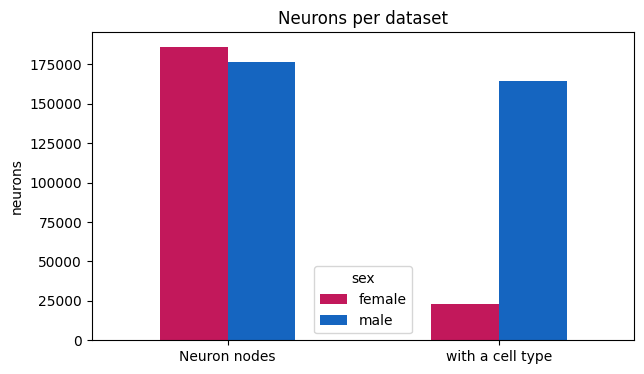

In [ ]:
counts[["Neuron nodes", "with a cell type"]].T.plot.bar(color=[SEX_COL["female"], SEX_COL["male"]], rot=0, figsize=(7, 4))
plt.ylabel("neurons"); plt.title("Neurons per dataset"); plt.show()

**Why is the male number so much larger?** The male dataset contains the *whole* nervous system (both brain hemispheres, optic lobes and ventral nerve cord); the hemibrain covers only part of one hemisphere. Raw totals therefore tell us about the datasets, not about sex. To compare sexes we have to look at **the same region** — next section.

---
## 3. Comparing neuropils
For each region: its **volume** (from the mesh), the number of **neurons with at least 10 synapses** in it, and its **pre- and postsynapses**.

In [ ]:
REGIONS = ["antennal lobe", "lateral horn", "calyx", "α lobe", "β lobe", "γ lobe", "ellipsoid body", "fan-shaped body",
           "SMP", "SIP", "AOTU"]
MIN_SYN = 10


def region_stats(sex, name):
    c, roi = CLIENTS[sex], ROI[sex][name]
    if roi is None:
        return {}
    info = c.meta.get("roiInfo", {}).get(roi, {})
    neurons, rc = fetch_neurons(NC(rois=[roi], client=c), client=c)
    rc = rc[rc["roi"] == roi]
    return {"region": name, "sex": sex, "volume (µm³)": mesh_volume_um3(sex, roi),
            "neurons": int(((rc["pre"] + rc["post"]) >= MIN_SYN).sum()),
            "pre": info.get("pre", rc["pre"].sum()), "post": info.get("post", rc["post"].sum())}


regions = pd.DataFrame([region_stats(s, r) for r in REGIONS for s in CLIENTS]).dropna(subset=["region"])
region_wide = regions.pivot(index="region", columns="sex").reindex(REGIONS)
region_wide.round(0)

In [ ]:
metrics = ["volume (µm³)", "neurons", "pre", "post"]
ratios = pd.DataFrame({m: region_wide[(m, "male")] / region_wide[(m, "female")] for m in metrics})
ax = ratios.plot.bar(figsize=(12, 4), width=0.8)
ax.axhline(1, c="k", ls="--"); ax.set_ylabel("male / female"); ax.set_title("Male/female ratio per region")
plt.show()
ratios.round(2)

Where are these regions? (right-hemisphere regions highlighted)

In [ ]:
reg_col = dict(zip(REGIONS, plt.cm.tab20.colors))
compare_anatomy(REGIONS, colours=reg_col, alpha=0.07, title="Regions compared in this section")

**Think:**
* Most regions should have similar volumes in both sexes. Which ones differ most?
* Neuron counts per region can be higher in the male partly because neurons from the *left* hemisphere that project to the right are complete in the male dataset but cut off in the hemibrain.

---
## 4. The α/β lobes in detail
The α/β lobes are formed by the axons of the **α/β Kenyon cells** (the last-born KC class). Each αβ-KC axon splits into a vertical **α** branch and a horizontal **β** branch. Here they are in both sexes:

In [ ]:
AB = ["α lobe", "β lobe"]
kcab = {sex: fetch_type(sex, "KCab.*", regex=True) for sex in CLIENTS}
example = {sex: kcab[sex][0]["bodyId"].iloc[:3].tolist() for sex in CLIENTS}     # 3 example αβ-KCs
compare_anatomy(MB_PARTS, example, colours=MB_COL, title="Three αβ Kenyon cells inside the mushroom body")

### 4.1 Size, synapses and connections of the α/β lobes

In [ ]:
def lobe_table(sex):
    c = CLIENTS[sex]
    rows = []
    for name in AB:
        roi = ROI[sex][name]
        n, rc = fetch_neurons(NC(rois=[roi], client=c), client=c)
        rc = rc[rc["roi"] == roi]
        info = c.meta.get("roiInfo", {}).get(roi, {})
        rows.append({"sex": sex, "lobe": name, "volume (µm³)": mesh_volume_um3(sex, roi),
                     "neurons (≥10 syn)": int(((rc["pre"] + rc["post"]) >= MIN_SYN).sum()),
                     "presynapses": info.get("pre", rc["pre"].sum()),
                     "postsynapses": info.get("post", rc["post"].sum()),
                     "downstream connections": rc["downstream"].sum(),
                     "upstream connections": rc["upstream"].sum()})
    return rows

lobes = pd.DataFrame(lobe_table("female") + lobe_table("male")).set_index(["lobe", "sex"]).sort_index()
lobes["synapses per µm³"] = (lobes["presynapses"] + lobes["postsynapses"]) / lobes["volume (µm³)"]
lobes.round(1)

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["volume (µm³)", "presynapses", "downstream connections", "synapses per µm³"]):
    lobes[col].unstack("sex")[["female", "male"]].plot.bar(ax=ax, color=[SEX_COL["female"], SEX_COL["male"]], rot=0)
    ax.set_title(col); ax.set_xlabel("")
plt.tight_layout(); plt.show()

* **downstream connections** — for every synapse, the number of postsynaptic partners it contacts (a T-bar usually faces several).
* **upstream connections** — the number of presynaptic partners contacting the neurons' postsynaptic sites.

### 4.2 Who is in the α/β lobes? Neurons per cell type

In [ ]:
def label(n, sex):
    if sex == "male" and "hemibrainType" in n:
        return n["hemibrainType"].fillna(n["type"])
    return n["type"]

inside = {}
for sex, c in CLIENTS.items():
    n, rc = fetch_neurons(NC(rois=[ROI[sex][x] for x in AB], roi_req="any", client=c), client=c)
    rc = rc[rc["roi"].isin([ROI[sex][x] for x in AB])].groupby("bodyId")[["pre", "post"]].sum()
    n = n.set_index("bodyId").join(rc, rsuffix="_lobe")
    n = n[(n["pre_lobe"] + n["post_lobe"]) >= MIN_SYN]
    inside[sex] = label(n, sex).fillna("untyped").str.replace(r"^(KCab|MBON|PAM|PPL)\S*", r"\1*", regex=True)
types_in_lobe = pd.DataFrame({s: v.value_counts() for s, v in inside.items()}).fillna(0).astype(int)
types_in_lobe.sort_values("female", ascending=False).head(12)

In [ ]:
kc_sub = pd.DataFrame({sex: label(kcab[sex][0], sex).value_counts() for sex in CLIENTS}).fillna(0).astype(int)
kc_sub.plot.bar(color=[SEX_COL["female"], SEX_COL["male"]], rot=0, figsize=(7, 4))
plt.ylabel("neurons (right side)"); plt.title("αβ Kenyon cell subtypes"); plt.show()
kc_sub

### 4.3 Partners and connection strength
Who do αβ-KCs talk to **inside the α/β lobes**, and how strongly? Male partners are labelled with their `hemibrainType` so the same partner has the same name in both sexes. Connection strength is given as **synapses per αβ-KC**, which corrects for different numbers of KCs.

In [ ]:
def kc_partners(sex, direction="out"):
    c = CLIENTS[sex]
    kcs = kcab[sex][0]["bodyId"].tolist()
    rois = [ROI[sex][x] for x in AB]
    props = ["type", "hemibrainType"] if sex == "male" else ["type"]
    if direction == "out":
        nn, conn = fetch_adjacencies(kcs, None, rois=rois, client=c, properties=props)
        side = "post"
    else:
        nn, conn = fetch_adjacencies(None, kcs, rois=rois, client=c, properties=props)
        side = "pre"
    conn = merge_neuron_properties(nn, conn, props)
    conn["partner"] = partner_label(conn, side)
    return conn.groupby("partner")["weight"].sum() / len(kcs)

out_strength = pd.DataFrame({s: kc_partners(s, "out") for s in CLIENTS}).fillna(0)
out_strength = out_strength.loc[out_strength.max(axis=1).sort_values(ascending=False).index]
out_strength.head(15).round(2)

In [ ]:
top = out_strength.head(25)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top[["female", "male"]].plot.barh(ax=axes[0], color=[SEX_COL["female"], SEX_COL["male"]])
axes[0].invert_yaxis(); axes[0].set_xlabel("output synapses per αβ-KC"); axes[0].set_title("Top output partners in α/β lobes")
both = out_strength[(out_strength > 0).all(axis=1)]
axes[1].scatter(both["female"], both["male"], c="grey")
for t in both.head(10).index:
    axes[1].annotate(t, (both.loc[t, "female"], both.loc[t, "male"]), fontsize=8)
lim = [both.min().min() * 0.5, both.max().max() * 2]
axes[1].plot(lim, lim, "k--"); axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("female: synapses per αβ-KC"); axes[1].set_ylabel("male: synapses per αβ-KC")
axes[1].set_title("Shared partners: connection strength")
plt.tight_layout(); plt.show()

only_f = out_strength[(out_strength["female"] > 0) & (out_strength["male"] == 0)]
only_m = out_strength[(out_strength["male"] > 0) & (out_strength["female"] == 0)]
print(f"Partner types in both: {len(both)} | only female: {len(only_f)} | only male: {len(only_m)}")
print("Strongest female-only:", list(only_f.head(5).index))
print("Strongest male-only:  ", list(only_m.head(5).index))

The strongest **shared** output partner of the αβ-KCs (preferably an MBON; KCs also synapse onto each other, so KCs are skipped), drawn in both sexes:

In [ ]:
non_kc = both[~both.index.str.startswith("KC")]
mbons = non_kc[non_kc.index.str.startswith("MBON")]          # prefer an output neuron if there is one
top_partner = (mbons if len(mbons) else non_kc).sum(axis=1).sort_values(ascending=False).index[0]
partner_cells = {sex: fetch_type(sex, top_partner)[0]["bodyId"].tolist() for sex in CLIENTS}
print("Top shared partner:", top_partner, {s: len(v) for s, v in partner_cells.items()})
compare_anatomy(MB_PARTS, partner_cells, colours=MB_COL, title=f"{top_partner}: strongest shared αβ-KC partner")

---
## 5. Neurons that look the same in both sexes
Some neurons are expected to be **isomorphic** (the same in both sexes). They show how similar two datasets look when there is no sexual dimorphism — any difference here is individual variation or methodology.

In [ ]:
ISO_TYPES = ["APL", "DPM", "MBON07", "PPL101", "EPG"]

def type_summary(htype):
    rows = []
    for sex in CLIENTS:
        n, _ = fetch_type(sex, htype)
        rows.append({"type": htype, "sex": sex, "neurons": len(n),
                     "pre / neuron": n["pre"].mean() if len(n) else np.nan,
                     "post / neuron": n["post"].mean() if len(n) else np.nan,
                     "volume µm³ / neuron": (n["size"] * VOXEL_UM3).mean() if "size" in n and len(n) else np.nan})
    return pd.DataFrame(rows)

iso = pd.concat([type_summary(t) for t in ISO_TYPES]).set_index(["type", "sex"])
iso.round(1)

In [ ]:
iso_ratio = (iso.xs("male", level="sex") / iso.xs("female", level="sex"))[["neurons", "pre / neuron", "post / neuron"]]
BASELINE = iso_ratio["pre / neuron"].median()
print(f"Median male/female ratio of presynapses per neuron in isomorphic types: {BASELINE:.2f}")
iso_ratio.round(2)

APL — one giant neuron per hemisphere that covers the whole mushroom body — in both sexes:

In [ ]:
apl = {sex: fetch_type(sex, "APL")[0]["bodyId"].tolist() for sex in CLIENTS}
compare_anatomy(MB_PARTS, apl, colours=MB_COL, title="APL (isomorphic)")

Change `ISO_PLOT` to look at the other isomorphic types with their neuropils:

In [ ]:
ISO_PLOT, ISO_ROIS = "EPG", ["ellipsoid body", "protocerebral bridge", "fan-shaped body"]
cells_ = {sex: fetch_type(sex, ISO_PLOT)[0]["bodyId"].tolist() for sex in CLIENTS}
compare_anatomy(ISO_ROIS, cells_, colours=dict(zip(ISO_ROIS, plt.cm.Set2.colors)), title=f"{ISO_PLOT} (isomorphic)")

---
## 6. Sexually dimorphic and sex-specific neurons
The male CNS annotates neurons with a `dimorphism` label. Berg *et al.* (2025) report **331 sex-specific** and **114 sexually dimorphic** cell types; they are concentrated in higher-order protocerebral regions rather than the sensory periphery, and most male-specific central-brain neurons express *fruitless* and/or *doublesex*.

In [ ]:
dimorphic = fetch_custom(
    "MATCH (n:Neuron) WHERE n.dimorphism IS NOT NULL "
    "RETURN n.bodyId AS bodyId, n.type AS type, n.hemibrainType AS hemibrainType, "
    "n.dimorphism AS dimorphism, n.superclass AS superclass, n.fruDsx AS fruDsx", client=male)
print(dimorphic["dimorphism"].value_counts().to_string())

In [ ]:
pd.crosstab(dimorphic["superclass"].fillna("unknown"), dimorphic["dimorphism"]).head(12)

### 6.1 pC1 / P1 — a cluster with different members in each sex
* **Males:** P1 neurons (within the pC1 cluster) promote courtship and aggression and are male-specific (Berg *et al.*).
* **Females:** pC1a–e; **pC1d and pC1e** are female-specific in the male CNS dimorphism resource. pC1d, together with aIPg neurons, is a core node of the female aggression circuit (Schretter *et al.* 2020).

In [ ]:
pc1 = {"female": fetch_neurons(NC(type="pC1.*", client=female), client=female)[0],
       "male": fetch_neurons(NC(type="P1_.*|pC1.*", client=male), client=male)[0]}
for sex, n in pc1.items():
    print(sex.upper(), len(n), "neurons:", n["type"].value_counts().sort_index().to_dict())
compare_anatomy(["SMP", "SIP", "AVLP", "α lobe", "β lobe"], {s: n["bodyId"].tolist() for s, n in pc1.items()},
                colours=dict(zip(["SMP", "SIP", "AVLP", "α lobe", "β lobe"], plt.cm.Set2.colors)),
                title="pC1 (female) vs P1/pC1 (male)")

### 6.2 mAL — same lineage, different neurons
The male CNS dimorphism resource lists `mAL_m1`–`mAL_m11` as male-specific and `mAL_f1`–`mAL_f4` as female-specific. In males a male-specific GABAergic neuron (vPN1) inhibits mAL, which inhibits P1 (Berg *et al.*).

In [ ]:
mal = {sex: fetch_neurons(NC(type="mAL.*", client=c), client=c)[0] for sex, c in CLIENTS.items()}
for sex, n in mal.items():
    print(sex.upper(), len(n), "neurons:", n["type"].value_counts().sort_index().to_dict())
compare_anatomy(["SMP", "SIP", "lateral horn", "AVLP"], {s: n["bodyId"].tolist() for s, n in mal.items()},
                colours=dict(zip(["SMP", "SIP", "lateral horn", "AVLP"], plt.cm.Set2.colors)), title="mAL neurons")

### 6.3 AOTU008 — a dimorphic neuron with extra male projections
AOTU008 receives visual input from LC10a neurons. In males it has **ventral axonal projections absent in females**, and 57 % of its output goes to sex-specific or dimorphic partners (Berg *et al.*).

In [ ]:
aotu = {sex: fetch_type(sex, "AOTU008") for sex in CLIENTS}
compare_anatomy(["AOTU", "SMP", "SIP", "AVLP", "LAL"], {s: v[0]["bodyId"].tolist() for s, v in aotu.items()},
                colours=dict(zip(["AOTU", "SMP", "SIP", "AVLP", "LAL"], plt.cm.Set2.colors)), title="AOTU008")

In [ ]:
def output_fraction(sex, n, r):
    prim = set(CLIENTS[sex].primary_rois)
    rr = r[r["roi"].isin(prim)].groupby("roi")["pre"].sum()
    return rr / rr.sum()

aotu_out = pd.DataFrame({s: output_fraction(s, *v) for s, v in aotu.items()}).fillna(0)
aotu_out = aotu_out.loc[aotu_out.max(axis=1).sort_values(ascending=False).index[:10]]
aotu_out.plot.barh(color=[SEX_COL["female"], SEX_COL["male"]], figsize=(7, 5)).invert_yaxis()
plt.xlabel("fraction of AOTU008 presynapses"); plt.title("Where does AOTU008 make its outputs?"); plt.show()

### 6.4 MZ_lv2PN — pheromone input only in males
A dimorphic antennal-lobe projection neuron: in males it receives input from the **DA1 and VL2a** glomeruli (pheromone channels), in females it does not (Berg *et al.*).

In [ ]:
mz = {sex: fetch_type(sex, "MZ_lv2PN")[0] for sex in CLIENTS}
compare_anatomy(["antennal lobe", "lateral horn", "calyx"], {s: n["bodyId"].tolist() for s, n in mz.items()},
                colours=dict(zip(["antennal lobe", "lateral horn", "calyx"], plt.cm.Set2.colors)), title="MZ_lv2PN")

In [ ]:
def input_strength(sex, n):
    c = CLIENTS[sex]
    props = ["type", "hemibrainType"] if sex == "male" else ["type"]
    nn, conn = fetch_adjacencies(None, n["bodyId"].tolist(), client=c, properties=props)
    conn = merge_neuron_properties(nn, conn, props)
    conn["partner"] = partner_label(conn, "pre")
    s = conn.groupby("partner")["weight"].sum()
    return s / s.sum()

mz_in = pd.DataFrame({s: input_strength(s, n) for s, n in mz.items() if len(n)}).fillna(0)
mz_in = mz_in.loc[mz_in.max(axis=1).sort_values(ascending=False).index[:12]]
mz_in.plot.barh(color=[SEX_COL[s] for s in mz_in.columns], figsize=(7, 6)).invert_yaxis()
plt.xlabel("fraction of input synapses"); plt.title("MZ_lv2PN inputs"); plt.show()
print(mz_in[mz_in.index.str.contains("DA1|VL2a")].round(3))

---
# Exercises

**Exercise 1 — another lobe.** Repeat Section 4.1 for the **γ lobe** (`AB = ["γ lobe"]`) or the **α′/β′ lobes**. Is the male/female ratio of volume and synapses similar to the α/β lobes?

In [ ]:
# YOUR CODE HERE

**Exercise 2 — inputs to αβ-KCs.** Use `kc_partners(sex, "in")` to compare the **input** partners of αβ-KCs inside the lobes. Which partner types are present in only one sex?

In [ ]:
# YOUR CODE HERE

**Exercise 3 — your own isomorphic type.** Add a cell type you expect to be the same in both sexes to `ISO_TYPES`, plot it with `compare_anatomy`, and check whether its pre/neuron ratio is close to `BASELINE`.

In [ ]:
# YOUR CODE HERE

**Exercise 4 — female-specific pC1d/pC1e.** How many pC1d and pC1e neurons are in the hemibrain? Are there male neurons with `hemibrainType` pC1d or pC1e? Plot them.

In [ ]:
# YOUR CODE HERE

**Exercise 5 — explore dimorphic types.** From `dimorphic`, pick one dimorphic type that has a `hemibrainType`. Plot both sexes with suitable neuropils and compare pre/post per neuron with `type_summary`. Is the difference larger than `BASELINE`?

In [ ]:
# YOUR CODE HERE

**Exercise 6 — discussion (no code).**
1. Each connectome is one animal. What would you need to show that a difference is sex-specific and not individual variation?
2. Why do we compare against isomorphic types (`BASELINE`) instead of comparing raw numbers?
3. The hemibrain is cut off at its edges. How could that change neuron counts per neuropil and the number of partners per neuron?

---
### References
* Scheffer L.K. *et al.* (2020) A connectome and analysis of the adult *Drosophila* central brain. *eLife* 9:e57443.
* Berg S. *et al.* (2025) Sexual dimorphism in the complete connectome of the *Drosophila* male central nervous system. bioRxiv 10.1101/2025.10.09.680999 (published in *Cell*, 2026).
* Li F. *et al.* (2020) The connectome of the adult *Drosophila* mushroom body provides insights into function. *eLife* 9:e62576.
* Schretter C.E. *et al.* (2020) Cell types and neuronal circuitry underlying female aggression in *Drosophila*. *eLife* 9:e58942.
* Male CNS project page and dimorphism explorer: <https://male-cns.janelia.org>